In [1]:
import pandas as pd
import numpy as np

##### =====================================================
# 1. LOAD DATASETS
##### =====================================================

In [2]:
campaigns = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.7\my_working\datasets\dim_campaigns.csv")
products = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.7\my_working\datasets\dim_products.csv")
stores = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.7\my_working\datasets\dim_stores.csv")
events = pd.read_csv(r"D:\DS\JC-Uttam-956e\codebasic final 30.06.26\DS\Virtual Internship - 1\2.7\my_working\datasets\fact_events.csv")

##### =====================================================
## Q1. How many duplicate rows were removed from the events DataFrame based on store_id, campaign_id, and product_code?
##### =====================================================

In [19]:
# Standardize column names
dataframes = {
    "Events": events,
    "Campaigns": campaigns,
    "Products": products,
    "Stores": stores
}
for name , df in dataframes.items():
    df.columns = df.columns.str.strip()

In [20]:
# 1. Count rows before removing duplicates
before_count = len(events)

# 2. Count duplicate rows
duplicate_count = events.duplicated(
    subset=["store_id", "campaign_id", "product_code"]
).sum()

# 3. Remove duplicates
events.drop_duplicates(
    subset=["store_id", "campaign_id", "product_code"],
    keep="first",
    inplace=True
)

# 4. Count rows after removing duplicates
after_count = len(events)

# 5. Display results
print("Total rows before removing duplicates:", before_count)
print("Total duplicate rows removed:", duplicate_count)
print("Total rows after removing duplicates:", after_count)

Total rows before removing duplicates: 1500
Total duplicate rows removed: 0
Total rows after removing duplicates: 1500


#### =====================================================
## Q2. CITIES HAVING MORE THAN 5 STORES
#### =====================================================

In [17]:
city_store_count = stores.groupby("city")["store_id"].nunique()

cities_more_than_5 = city_store_count[city_store_count>5]

print("\nQ2. Cities with more than 5 stores:")
print(cities_more_than_5)
print("Total cities:", len(cities_more_than_5))



Q2. Cities with more than 5 stores:
city
Bengaluru    10
Chennai       8
Hyderabad     7
Name: store_id, dtype: int64
Total cities: 3


##### =====================================================
## Q3. IMPUTE MISSING QUANTITY USING MEDIAN
##### =====================================================

In [6]:
missing_count = events['quantity_sold(before_promo)'].isnull().sum()

median_quantity = events['quantity_sold(before_promo)'].median()

events['quantity_sold(before_promo)'] = events['quantity_sold(before_promo)'].fillna(
    median_quantity)

print("\nQ3. Missing values filled:", missing_count)
print("Median used:", median_quantity)


Q3. Missing values filled: 20
Median used: 78.0


##### =====================================================
## Q4. CATEGORY WITH LOWEST BASE PRICE
##### =====================================================

In [7]:
lowest_price = events["base_price(before_promo)"].min()

result = events[
    events["base_price(before_promo)"] == lowest_price
].merge(products[["product_code","category"]], on = "product_code")

print("\nQ3.Category with the Lowest Base Price?")
print(result["category"].unique())


Q3.Category with the Lowest Base Price?
['Personal Care']


##### =====================================================
## Q5. What is the total BOGOF quantity sold during the Diwali promotion?
##### =====================================================

In [8]:
# 1. Filter Diwali campaign
diwali = campaigns[
    campaigns["campaign_name"] == "Diwali"]

# 2. Filter BOGOF promotion and merge campaign information
result = events.merge(
    diwali[["campaign_id"]],
    on = "campaign_id",
    how="inner"
)

# 3. Filter BOGOF promo type
result = result[result["promo_type"]=="BOGOF"]

# 4. Calculate total quantity sold after promotion
total_quantity_sold = result["quantity_sold(after_promo)"].sum()

print("What is the total BOGOF quantity sold during the Diwali promotion ? :", total_quantity_sold)

What is the total BOGOF quantity sold during the Diwali promotion ? : 34461


##### =====================================================
## Q6. Which store had the highest Diwali promotional sales?
##### =====================================================

In [9]:
# Merge fact_events with dim_campaigns
df = events.merge(
    campaigns[["campaign_id", "campaign_name"]],
    on="campaign_id"
)

# Filter Diwali campaign and group by store
result = (
    df[df["campaign_name"] == "Diwali"]
    .groupby("store_id")["quantity_sold(after_promo)"]
    .sum()
    .idxmax()
)

print("Store with highest quantity sold:", result)

Store with highest quantity sold: STCHE-4


##### =====================================================
## Q7. Compare total quantities sold before and after promotions for Sankranti and Diwali.
##### =====================================================

,quantity_sold(before_promo),quantity_sold(after_promo),sales_increase
campaign_name,,,
Diwali,109756.0,183404,73648.0
Sankranti,97894.0,252069,154175.0


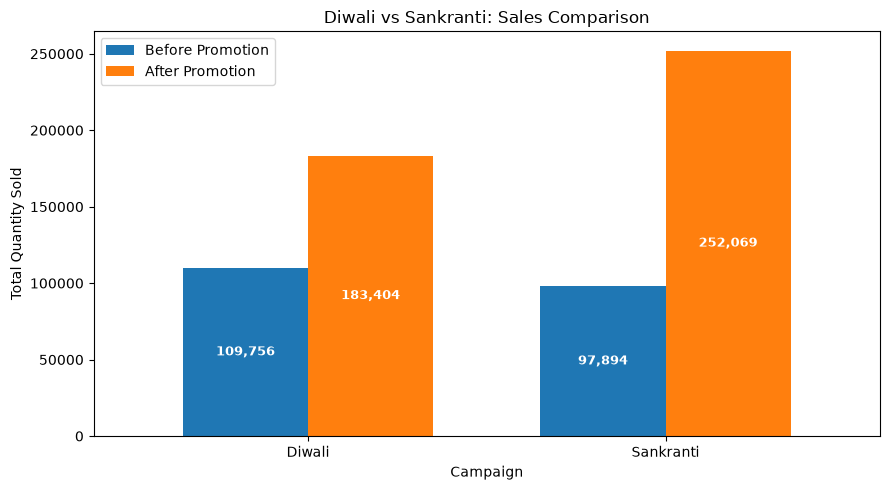

Campaign with greater sales increase: Sankranti


In [10]:
import matplotlib.pyplot as plt

# 1. Merge campaign information
df = events.merge(
    campaigns[["campaign_id", "campaign_name"]],
    on="campaign_id"
)

# 2. Calculate campaign-wise total quantities
result = df.groupby("campaign_name")[
    ["quantity_sold(before_promo)", "quantity_sold(after_promo)"]
].sum()

# 3. Calculate sales increase
result["sales_increase"] = (
    result["quantity_sold(after_promo)"] -
    result["quantity_sold(before_promo)"]
)

# 4. Display results
display(result)

# 5. Create comparison chart
ax = result[
    ["quantity_sold(before_promo)", "quantity_sold(after_promo)"]
].plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

# 6. Display values inside bars
for container in ax.containers:
    labels = [f"{bar.get_height():,.0f}" for bar in container]
    ax.bar_label(
        container,
        labels=labels,
        label_type="center",
        color="white",
        fontweight="bold",
        fontsize=9
    )

# 7. Chart formatting
plt.title("Diwali vs Sankranti: Sales Comparison")
plt.xlabel("Campaign")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)
plt.legend(["Before Promotion", "After Promotion"])
plt.tight_layout()
plt.show()

# 8. Identify campaign with greater sales increase
print(
    "Campaign with greater sales increase:",
    result["sales_increase"].idxmax()
)

##### =====================================================
## Q8. Which product had the highest IR% during the Sankranti campaign, and what was its percentage?
##### =====================================================

In [11]:
# Filter Sankranti campaign
df = events.merge(campaigns, on="campaign_id")

sankranti = df[df["campaign_name"] == "Sankranti"].copy()

# Calculate revenue before and after promotion

sankranti["revenue_before"] = (sankranti["base_price(before_promo)"]*
                              sankranti["quantity_sold(before_promo)"]
                              )

sankranti["revenue_after"] = (sankranti["base_price(after_promo)"]*
                              sankranti["quantity_sold(after_promo)"]
                              )

# Aggregate revenue product-wise
product_revenue = sankranti.groupby("product_code").agg(
    revenue_before= ("revenue_before","sum"),
    revenue_after= ("revenue_after","sum")
).reset_index()

# Calculate IR%
product_revenue["IR%"] = (product_revenue['revenue_after']-
                          product_revenue['revenue_before'])/product_revenue['revenue_before']*100

# Get product with highest IR%
result = product_revenue.loc[product_revenue["IR%"].idxmax()]

# Get product name
result = result.to_frame().T.merge(
    products, on="product_code"
)

print(result[["product_name", "IR%"]])


              product_name        IR%
0  Atliq_Suflower_Oil (1L)  91.826561


##### =====================================================
## Q9. To find the store in Visakhapatnam with the lowest ISU% during the Diwali campaign.
##### =====================================================

In [12]:
# Merge fact_events with campaigns and stores
df= events.merge(campaigns,on = "campaign_id")
df = df.merge(stores, on = "store_id")

# Filter Diwali campaign and Visakhapatnam city
diwali = df[
    (df["campaign_name"]=="Diwali") & 
    (df["city"]== "Visakhapatnam")
].copy()

# Calculate total units sold before and after promotion
store_sales = diwali.groupby("store_id").agg(
    units_before=("quantity_sold(before_promo)","sum"),
    units_after=("quantity_sold(after_promo)","sum")
).reset_index()

# Calculate ISU%
store_sales["ISU%"] = (
    (store_sales["units_after"] - store_sales["units_before"]) /
    store_sales["units_before"]
) * 100

# Find store with lowest ISU%
result = store_sales.loc[store_sales["ISU%"].idxmin()]

# Get store details
result = result.to_frame().T.merge(stores, on="store_id")

print(result[["store_id", "city", "ISU%"]])

  store_id           city       ISU%
0  STVSK-3  Visakhapatnam  49.213483


##### =====================================================
## 10.Which Sankranti promo type had negative IR% and ISU%?
##### =====================================================

In [13]:
# Merge fact_events with campaign details
df = events.merge(campaigns, on="campaign_id")

# Filter Sankranti campaign
sankranti = df[df["campaign_name"] == "Sankranti"].copy()

# Calculate revenue before and after promotion
sankranti["revenue_before"] = (
    sankranti["base_price(before_promo)"] *
    sankranti["quantity_sold(before_promo)"]
)

sankranti["revenue_after"] = (
    sankranti["base_price(after_promo)"] *
    sankranti["quantity_sold(after_promo)"]
)

# Group by promotion type
promo_analysis = sankranti.groupby("promo_type").agg(
    revenue_before=("revenue_before", "sum"),
    revenue_after=("revenue_after", "sum"),
    units_before=("quantity_sold(before_promo)", "sum"),
    units_after=("quantity_sold(after_promo)", "sum")
).reset_index()

# Calculate IR%
promo_analysis["IR%"] = (
    (promo_analysis["revenue_after"] - promo_analysis["revenue_before"]) /
    promo_analysis["revenue_before"]
) * 100

# Calculate ISU%
promo_analysis["ISU%"] = (
    (promo_analysis["units_after"] - promo_analysis["units_before"]) /
    promo_analysis["units_before"]
) * 100

# Filter promotion types with both negative metrics
result = promo_analysis[
    (promo_analysis["IR%"] < 0) &
    (promo_analysis["ISU%"] < 0)
]

print(result[["promo_type", "IR%", "ISU%"]])

  promo_type        IR%      ISU%
0    25% OFF -39.329552 -19.60309
